# Practical 1 · Neural networks, step by step

**Part A:** build a neural network **from scratch** with NumPy: one neuron, layers, a loss, backpropagation and training. Nothing hidden.
**Part B:** do the same with **PyTorch** (the library used to build GPT-style models), then teach a network to read handwritten digits.

Run each cell with **Shift + Enter**. Read the text first, predict what will happen, then run.

# Part A · From scratch with NumPy

## A0 · Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(0)
plt.rcParams['figure.figsize'] = (6, 4)
print('ready')

ready


## A1 · One neuron
A neuron does two things:
1. **Weighted sum:** multiply each input by a weight, add them up, add a bias: `z = w1*x1 + w2*x2 + b`
2. **Activation:** squeeze `z` with a function, here the **sigmoid**, which turns any number into 0–1.

Example: decide whether a student passes from *hours studied* and *hours slept*.

In [2]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

x = np.array([6.0, 7.0])        # inputs: 6 hours studied, 7 hours slept
w = np.array([0.8, 0.3])        # weights: studying matters more than sleep (we chose these by hand for now)
b = -6.0                        # bias: how hard it is to pass at all

z = np.dot(w, x) + b            # 0.8*6 + 0.3*7 - 6
p = sigmoid(z)
print(f'weighted sum z = {z:.2f}')
print(f'output (probability of passing) = {p:.3f}')

weighted sum z = 0.90
output (probability of passing) = 0.711


**This one neuron is exactly logistic regression** (ML handbook, Part 5): a weighted sum squeezed by a sigmoid. A neural network is many of these, connected in layers. Training means finding good weights automatically instead of choosing them by hand.

## A2 · Activation functions

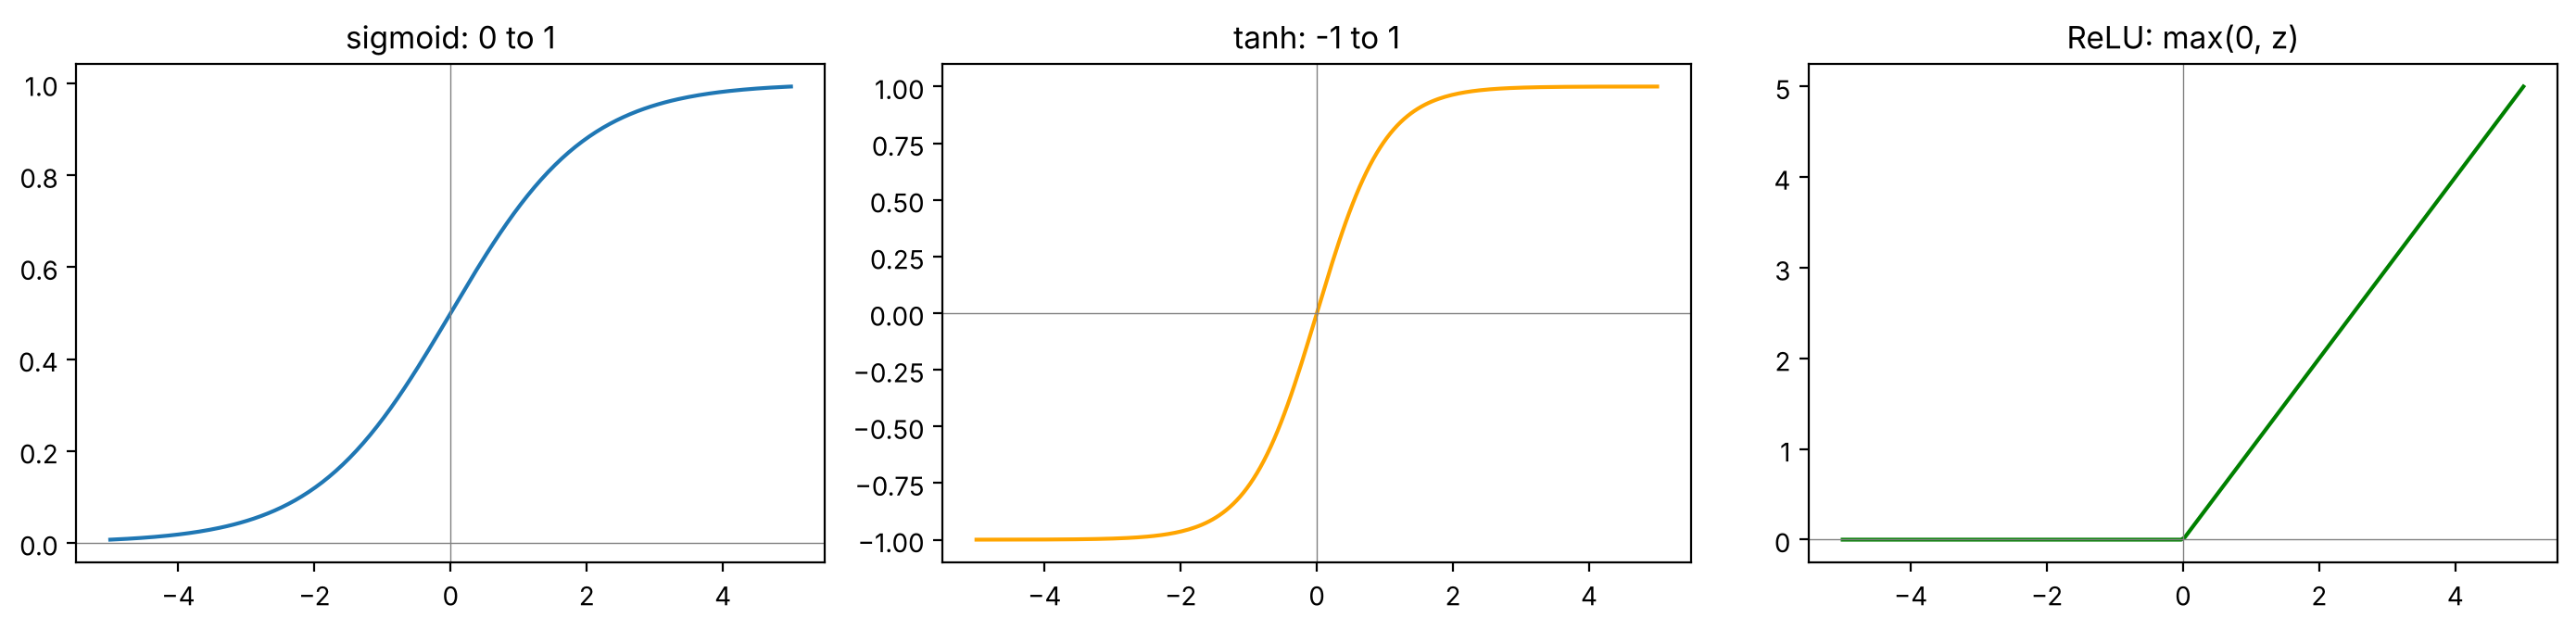

In [3]:
z = np.linspace(-5, 5, 200)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
ax[0].plot(z, sigmoid(z)); ax[0].set_title('sigmoid: 0 to 1')
ax[1].plot(z, np.tanh(z), color='orange'); ax[1].set_title('tanh: -1 to 1')
ax[2].plot(z, np.maximum(0, z), color='green'); ax[2].set_title('ReLU: max(0, z)')
for a in ax: a.axhline(0, color='grey', lw=.5); a.axvline(0, color='grey', lw=.5)
plt.tight_layout(); plt.show()

**Why do we need them?** Without an activation, stacking layers is pointless: two linear layers are still one linear layer. Proof with numbers:

In [4]:
W1 = np.random.randn(3, 2); W2 = np.random.randn(1, 3)
x = np.array([1.5, -2.0])
two_layers = W2 @ (W1 @ x)          # layer 1 then layer 2, no activation
one_layer = (W2 @ W1) @ x           # a single combined layer
print('two linear layers:', two_layers.round(4))
print('one combined layer:', one_layer.round(4), '-> identical')

two linear layers: [1.7189]
one combined layer: [1.7189] -> identical


The activation (a bend) between layers is what lets a network learn **curved** patterns.

## A3 · What one neuron cannot learn: XOR
XOR ("exclusive or") is 1 when exactly one input is 1. Plot the four points: no single straight line separates the 1s from the 0s.

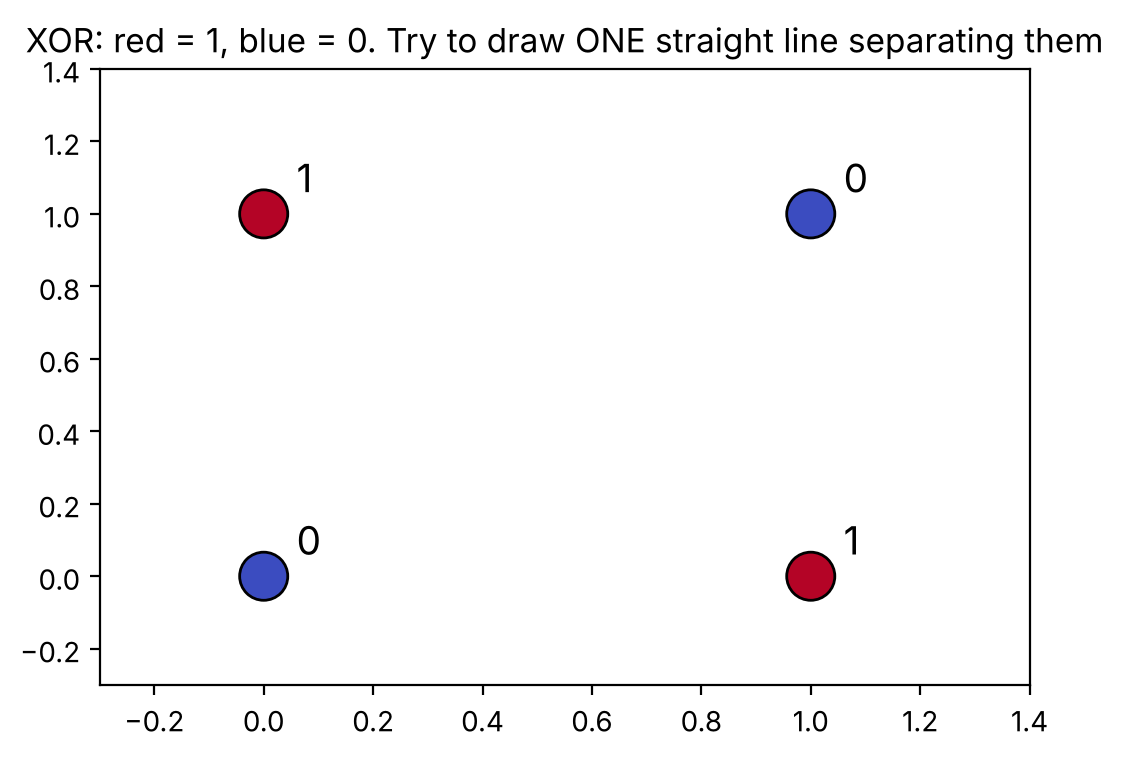

In [5]:
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y = np.array([0, 1, 1, 0], dtype=float)
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', s=300, edgecolors='k')
for (a, b_), t in zip(X, y): plt.text(a + .06, b_ + .06, f'{int(t)}', fontsize=14)
plt.title('XOR: red = 1, blue = 0. Try to draw ONE straight line separating them'); plt.xlim(-.3, 1.4); plt.ylim(-.3, 1.4); plt.show()

Let's prove it: train a single neuron (logistic regression) on XOR.

In [6]:
from sklearn.linear_model import LogisticRegression
single = LogisticRegression().fit(X, y)
print('one neuron predicts:', single.predict_proba(X)[:, 1].round(2), ' (truth: 0 1 1 0)')
print('accuracy:', single.score(X, y))

one neuron predicts: [0.5 0.5 0.5 0.5]  (truth: 0 1 1 0)
accuracy: 0.5


It is stuck near 0.5 for every point. **One neuron can only draw one straight line.** We need a hidden layer.

## A4 · A network with a hidden layer: the forward pass
Our network: **2 inputs → 4 hidden neurons (tanh) → 1 output neuron (sigmoid)**.

With matrices, a whole layer is one line: `hidden = tanh(X @ W1 + b1)`. Watch the **shapes**: they are the most common source of bugs.

In [7]:
def init_params(n_in=2, n_hidden=4, n_out=1, seed=0):
    rng = np.random.default_rng(seed)
    return {'W1': rng.normal(0, 1, (n_in, n_hidden)), 'b1': np.zeros(n_hidden),
            'W2': rng.normal(0, 1, (n_hidden, n_out)), 'b2': np.zeros(n_out)}

def forward(X, p):
    z1 = X @ p['W1'] + p['b1']      # (n, 2) @ (2, 4) -> (n, 4)
    h = np.tanh(z1)                 # hidden layer activations
    z2 = h @ p['W2'] + p['b2']      # (n, 4) @ (4, 1) -> (n, 1)
    out = sigmoid(z2)               # probability
    return out, (z1, h, z2)

params = init_params()
out, cache = forward(X, params)
print('X shape:', X.shape, '| hidden shape:', cache[1].shape, '| output shape:', out.shape)
print('untrained outputs:', out.ravel().round(3))
n_params = sum(v.size for v in params.values())
print('number of parameters (weights + biases):', n_params)

X shape: (4, 2) | hidden shape: (4, 4) | output shape: (4, 1)
untrained outputs: [0.5   0.354 0.433 0.359]
number of parameters (weights + biases): 17


Random weights give random answers. Now we need (1) a way to measure how wrong we are and (2) a way to fix the weights.

## A5 · The loss: how wrong are we?
For yes/no outputs we use **binary cross-entropy** (log loss): it punishes confident wrong answers heavily.

In [8]:
def bce(y_true, p, eps=1e-9):
    p = np.clip(p, eps, 1 - eps)
    return -np.mean(y_true * np.log(p) + (1 - y_true) * np.log(1 - p))

print('loss of the untrained network:', round(bce(y, out.ravel()), 4))
print('loss of always saying 0.5   :', round(bce(y, np.full(4, 0.5)), 4))
print('loss of a perfect answer    :', round(bce(y, np.array([0.001, .999, .999, .001])), 4))

loss of the untrained network: 0.7535
loss of always saying 0.5   : 0.6931
loss of a perfect answer    : 0.001


## A6 · Backpropagation: who is to blame, and by how much?
To improve, every weight needs its **gradient**: "if I nudge this weight up a little, does the loss go up or down, and how fast?"

**Backpropagation** computes all gradients at once by applying the **chain rule** from the output backwards, layer by layer.

### A6a · The chain rule on a tiny example
`loss = (w*x - y)²`. The chain rule says: d loss/dw = 2(w*x - y) · x. Let's check it against a **numerical** estimate (nudge w by a tiny amount and measure).

In [9]:
w_, x_, y_ = 3.0, 2.0, 5.0
loss_fn = lambda w: (w * x_ - y_) ** 2
analytic = 2 * (w_ * x_ - y_) * x_
numeric = (loss_fn(w_ + 1e-5) - loss_fn(w_ - 1e-5)) / 2e-5
print(f'chain rule: {analytic:.5f} | nudge-and-measure: {numeric:.5f}')

chain rule: 4.00000 | nudge-and-measure: 4.00000


### A6b · Backpropagation for our network
Going backwards from the loss (the formulas follow from the chain rule; the sigmoid + cross-entropy combination simplifies nicely to `out - y`):

In [10]:
def backward(X, y, p, cache):
    z1, h, z2 = cache
    out = sigmoid(z2)
    n = len(X)
    d_z2 = (out - y.reshape(-1, 1)) / n            # error at the output
    grads = {'W2': h.T @ d_z2, 'b2': d_z2.sum(axis=0)}
    d_h = d_z2 @ p['W2'].T                          # blame passed back to the hidden layer
    d_z1 = d_h * (1 - np.tanh(z1) ** 2)             # through tanh (its slope is 1 - tanh^2)
    grads['W1'] = X.T @ d_z1
    grads['b1'] = d_z1.sum(axis=0)
    return grads

# gradient check: compare backprop with nudge-and-measure for one weight
out, cache = forward(X, params)
g = backward(X, y, params, cache)
p2 = {k: v.copy() for k, v in params.items()}; p2['W1'][0, 1] += 1e-5
p3 = {k: v.copy() for k, v in params.items()}; p3['W1'][0, 1] -= 1e-5
numeric = (bce(y, forward(X, p2)[0].ravel()) - bce(y, forward(X, p3)[0].ravel())) / 2e-5
print(f"backprop gradient for W1[0,1]: {g['W1'][0, 1]:.6f}")
print(f'nudge-and-measure estimate  : {numeric:.6f}  -> they match, so our backprop is correct')

backprop gradient for W1[0,1]: 0.068377
nudge-and-measure estimate  : 0.068377  -> they match, so our backprop is correct


## A7 · Training: repeat forward → loss → backward → update
**Gradient descent:** move every weight a small step against its gradient. One full pass over the data = one **epoch**.

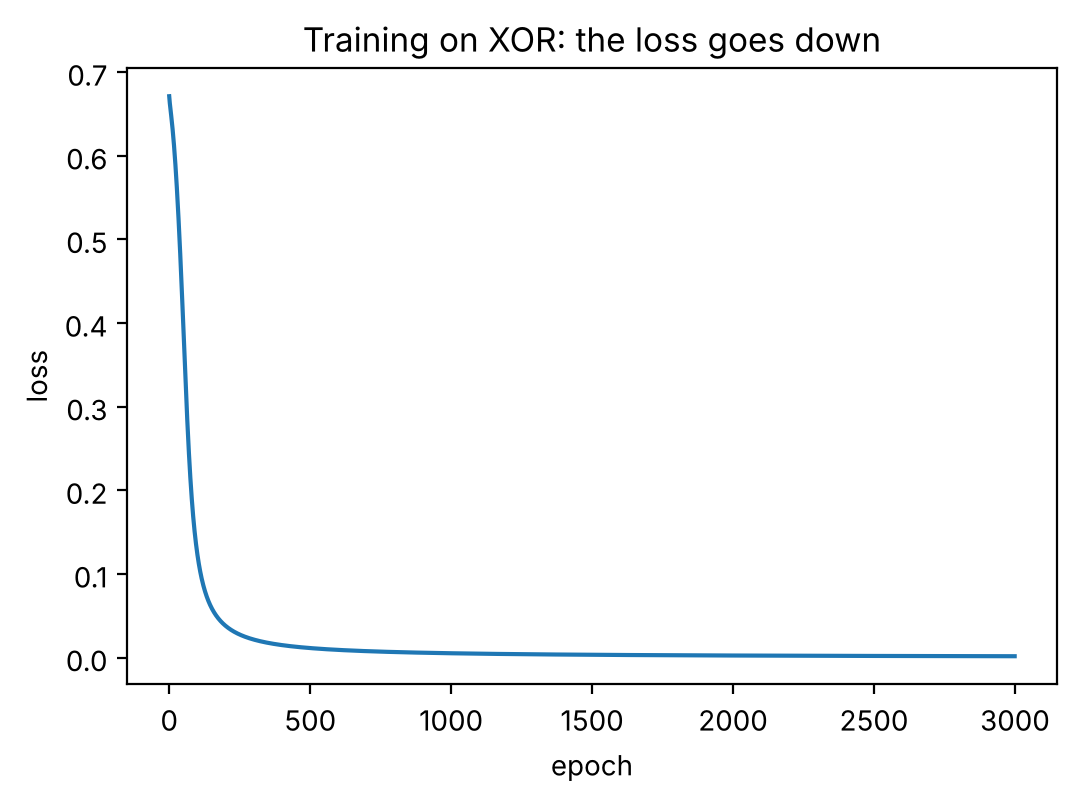

trained outputs: [0.    0.998 0.998 0.003]  (truth: 0 1 1 0)


In [11]:
def train(X, y, n_hidden=4, lr=0.5, epochs=3000, seed=1):
    p = init_params(X.shape[1], n_hidden, 1, seed)
    history = []
    for epoch in range(epochs):
        out, cache = forward(X, p)
        history.append(bce(y, out.ravel()))
        grads = backward(X, y, p, cache)
        for k in p:
            p[k] -= lr * grads[k]          # the learning step
    return p, history

params, history = train(X, y)
plt.plot(history); plt.xlabel('epoch'); plt.ylabel('loss'); plt.title('Training on XOR: the loss goes down'); plt.show()
print('trained outputs:', forward(X, params)[0].ravel().round(3), ' (truth: 0 1 1 0)')

**Solved.** The hidden layer learned to bend the boundary. Let's see the boundary it drew:

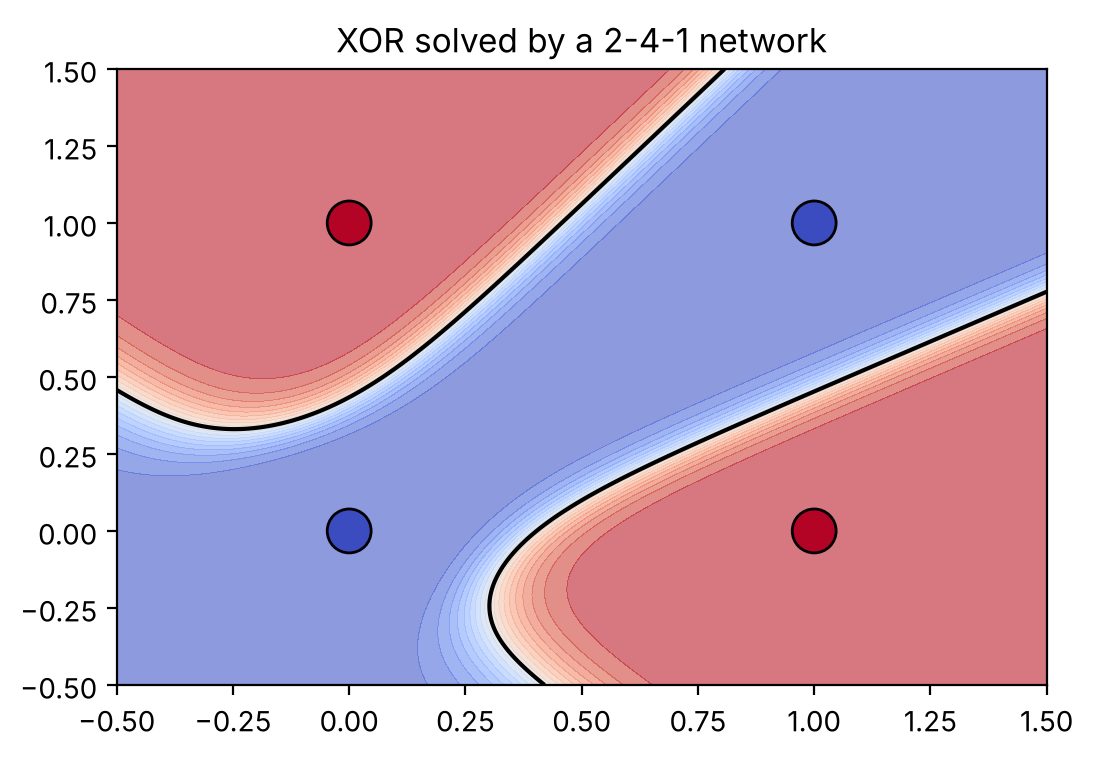

In [12]:
def plot_boundary(predict, X, y, title):
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - .5, X[:, 0].max() + .5, 300), np.linspace(X[:, 1].min() - .5, X[:, 1].max() + .5, 300))
    zz = predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    plt.contourf(xx, yy, zz, levels=20, cmap='coolwarm', alpha=.6); plt.contour(xx, yy, zz, levels=[.5], colors='k')
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', edgecolors='k', s=40 if len(X) > 10 else 250); plt.title(title); plt.show()

plot_boundary(lambda G: forward(G, params)[0].ravel(), X, y, 'XOR solved by a 2-4-1 network')

### A7a · Does the starting point matter? Try different random seeds
Training starts from **random** weights. Let's train the same network from four different random starts:

In [13]:
for seed in [0, 1, 2, 3]:
    p_, h_ = train(X, y, seed=seed)
    print(f'seed {seed}: outputs {forward(X, p_)[0].ravel().round(3)}  final loss {h_[-1]:.3f}')

seed 0: outputs [0.001 0.499 0.999 0.501]  final loss 0.348
seed 1: outputs [0.    0.998 0.998 0.003]  final loss 0.002


seed 2: outputs [0.    0.999 0.999 0.001]  final loss 0.001
seed 3: outputs [0.    0.998 0.998 0.002]  final loss 0.002


Seed 0 gets **stuck**: it learns two of the four points and sits at 0.5 for the other two. Gradient descent only walks downhill from where it starts, and from that start it settled in a **local minimum**, a valley that isn't the deepest one.

Real networks avoid this with smarter starting weights, more neurons, momentum/Adam optimizers and lots of data. In very large networks this problem becomes much rarer. **Practical habit:** if training stalls, try another seed or optimizer before concluding the model can't learn.

### A7b · A harder shape: two interlocking moons

training accuracy on the moons: 0.985


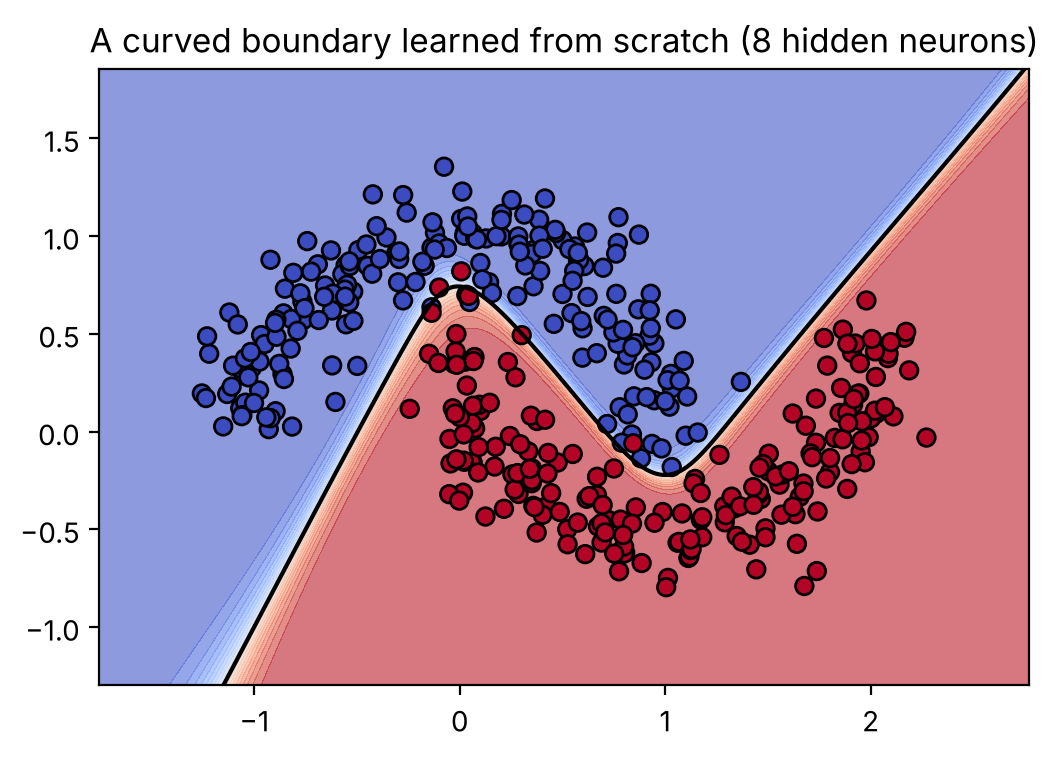

In [14]:
from sklearn.datasets import make_moons
Xm, ym = make_moons(400, noise=0.15, random_state=0)
pm, hist_m = train(Xm, ym.astype(float), n_hidden=8, lr=1.0, epochs=4000)
acc = ((forward(Xm, pm)[0].ravel() >= .5) == ym).mean()
print(f'training accuracy on the moons: {acc:.3f}')
plot_boundary(lambda G: forward(G, pm)[0].ravel(), Xm, ym, 'A curved boundary learned from scratch (8 hidden neurons)')

### A8 · Experiment: learning rate and hidden size

In [15]:
import pandas as pd
rows = []
for n_hidden in [1, 2, 8]:
    for lr in [0.01, 0.5, 5.0]:
        p_, h_ = train(Xm, ym.astype(float), n_hidden=n_hidden, lr=lr, epochs=2000)
        rows.append({'hidden neurons': n_hidden, 'learning rate': lr, 'final loss': round(h_[-1], 3),
                     'accuracy': round(((forward(Xm, p_)[0].ravel() >= .5) == ym).mean(), 3)})
pd.DataFrame(rows)

,hidden neurons,learning rate,final loss,accuracy
0,1,0.01,0.550,0.728
1,1,0.50,0.279,0.882
2,1,5.00,0.312,0.870
3,2,0.01,0.301,0.875
4,2,0.50,0.272,0.885
5,2,5.00,0.276,0.875
6,8,0.01,0.296,0.875
7,8,0.50,0.038,0.985
8,8,5.00,0.027,0.985


- **1 hidden neuron** ≈ a straight line: it can't fit the moons well.
- **Learning rate 0.01** is too timid: after 2,000 epochs it is still far from done (loss 0.30–0.55).
- **8 hidden neurons + a sensible learning rate (0.5–5)** fits the moons (98.5%). Here even 5.0 works, but in bigger networks a too-large rate makes the loss jump around or explode (ML handbook, Part 4).

Everything above (forward pass, loss, backpropagation, update) is exactly what happens inside GPT, just with billions of weights.

---
# Part B · The same with PyTorch

Writing backpropagation by hand doesn't scale. **PyTorch** computes gradients automatically (**autograd**) and runs on GPUs.

## B1 · Tensors and autograd

In [16]:
import torch
torch.manual_seed(0)

w = torch.tensor(3.0, requires_grad=True)       # track gradients for w
x, y_t = torch.tensor(2.0), torch.tensor(5.0)
loss = (w * x - y_t) ** 2
loss.backward()                                 # backpropagation, automatically
print('loss:', loss.item(), '| d loss / d w =', w.grad.item(), '(same as our chain-rule answer: 4.0)')

loss: 1.0 | d loss / d w = 4.0 (same as our chain-rule answer: 4.0)


## B2 · The moons network in PyTorch: the standard training loop

In [17]:
import torch.nn as nn
Xt = torch.tensor(Xm, dtype=torch.float32)
yt = torch.tensor(ym, dtype=torch.float32).unsqueeze(1)

model = nn.Sequential(nn.Linear(2, 8), nn.Tanh(), nn.Linear(8, 1))   # 2 -> 8 -> 1 (sigmoid is inside the loss)
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.05)

for epoch in range(500):
    optimizer.zero_grad()            # 1 clear old gradients
    logits = model(Xt)               # 2 forward pass
    loss = loss_fn(logits, yt)       # 3 loss
    loss.backward()                  # 4 backpropagation
    optimizer.step()                 # 5 update weights

acc = ((torch.sigmoid(model(Xt)) >= .5).float() == yt).float().mean().item()
print(f'final loss {loss.item():.3f} | accuracy {acc:.3f}')

final loss 0.030 | accuracy 0.985


The **five lines in the loop** are the heart of all deep learning, from this toy to GPT: *zero gradients → forward → loss → backward → step*.

**Adam** is a smarter optimizer than plain gradient descent: it adapts the step size for each weight. It is what LLMs are trained with.

## B3 · Reading handwritten digits
1,797 images of handwritten digits (8 × 8 pixels each) that ship with scikit-learn. Each image becomes 64 numbers; the network outputs 10 scores, one per digit.

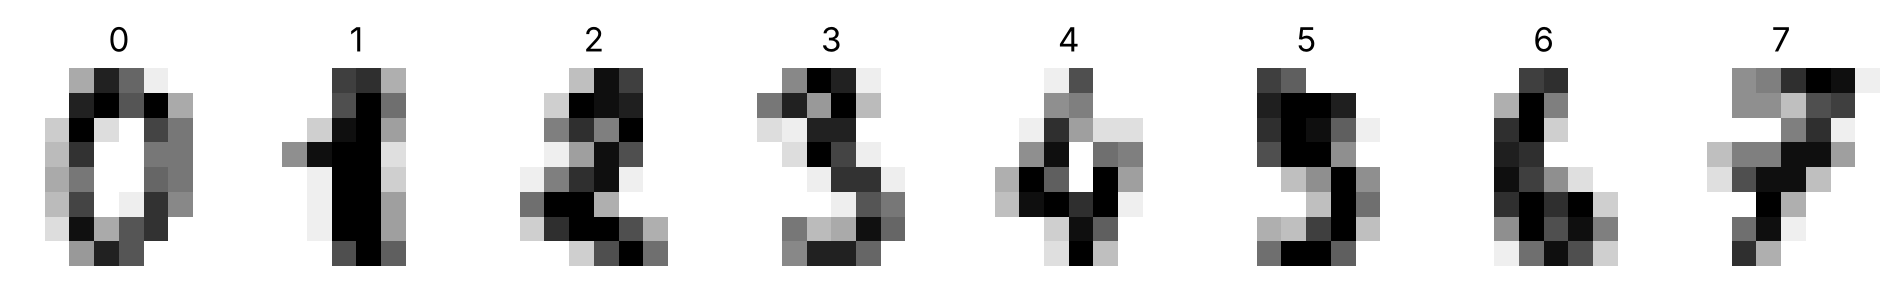

train torch.Size([1437, 64]) | test torch.Size([360, 64])


In [18]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
digits = load_digits()
fig, ax = plt.subplots(1, 8, figsize=(12, 2))
for i in range(8):
    ax[i].imshow(digits.images[i], cmap='gray_r'); ax[i].set_title(digits.target[i]); ax[i].axis('off')
plt.show()

X_tr, X_te, y_tr, y_te = train_test_split(digits.data / 16.0, digits.target, test_size=0.2, random_state=42, stratify=digits.target)
X_tr, X_te = torch.tensor(X_tr, dtype=torch.float32), torch.tensor(X_te, dtype=torch.float32)
y_tr, y_te = torch.tensor(y_tr), torch.tensor(y_te)
print('train', X_tr.shape, '| test', X_te.shape)

Pixel values were 0–16, so we divided by 16 (scaling, like StandardScaler). The network: **64 → 64 (ReLU) → 10**. For 10 classes we use **cross-entropy** loss, which applies **softmax** inside (turns 10 scores into probabilities that add to 1).

We train in **mini-batches** of 32 images: each step uses a small random batch, exactly how large models are trained.

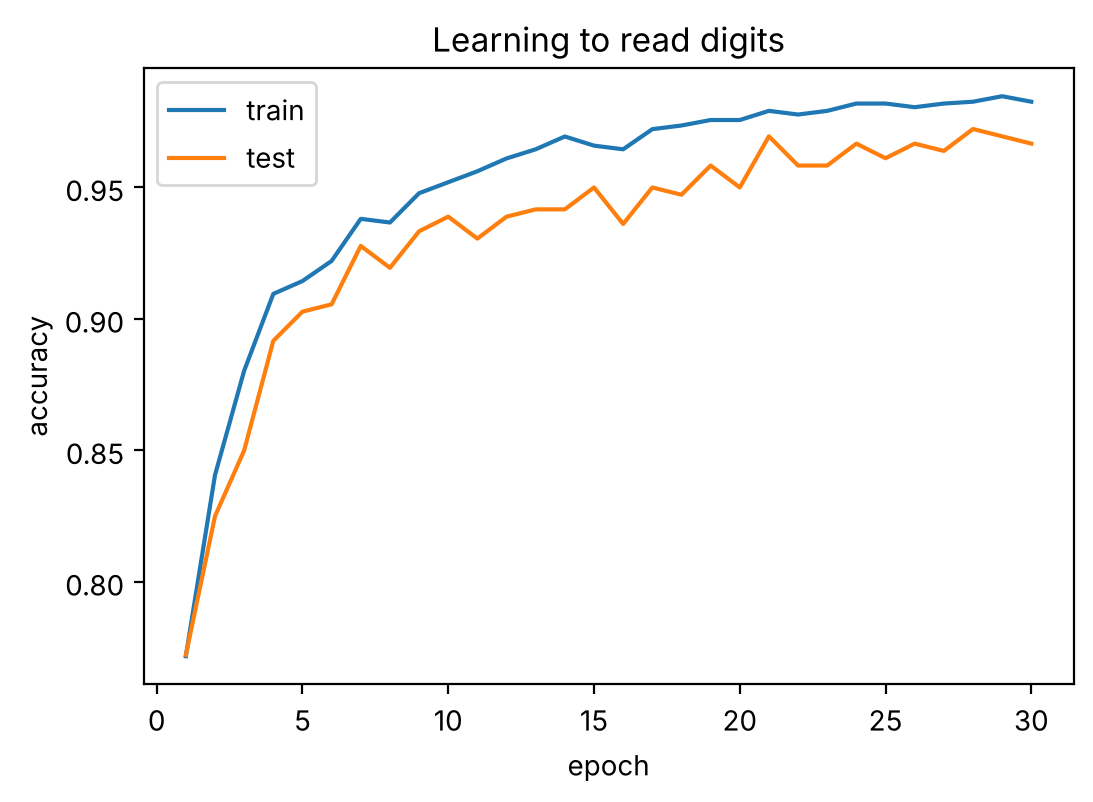

after 30 epochs: train 0.983, test 0.967
parameters: 4810


In [19]:
from torch.utils.data import TensorDataset, DataLoader
torch.manual_seed(0)
net = nn.Sequential(nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 10))
opt = torch.optim.Adam(net.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss()
loader = DataLoader(TensorDataset(X_tr, y_tr), batch_size=32, shuffle=True)

def accuracy(X, y):
    with torch.no_grad():
        return (net(X).argmax(dim=1) == y).float().mean().item()

log = []
for epoch in range(30):
    for xb, yb in loader:
        opt.zero_grad(); loss = loss_fn(net(xb), yb); loss.backward(); opt.step()
    log.append({'epoch': epoch + 1, 'train acc': accuracy(X_tr, y_tr), 'test acc': accuracy(X_te, y_te)})
log = pd.DataFrame(log)
plt.plot(log['epoch'], log['train acc'], label='train'); plt.plot(log['epoch'], log['test acc'], label='test')
plt.xlabel('epoch'); plt.ylabel('accuracy'); plt.legend(); plt.title('Learning to read digits'); plt.show()
print(f"after 30 epochs: train {log['train acc'].iloc[-1]:.3f}, test {log['test acc'].iloc[-1]:.3f}")
print('parameters:', sum(p.numel() for p in net.parameters()))

## B4 · What does it get wrong?

test images misread: 12 of 360


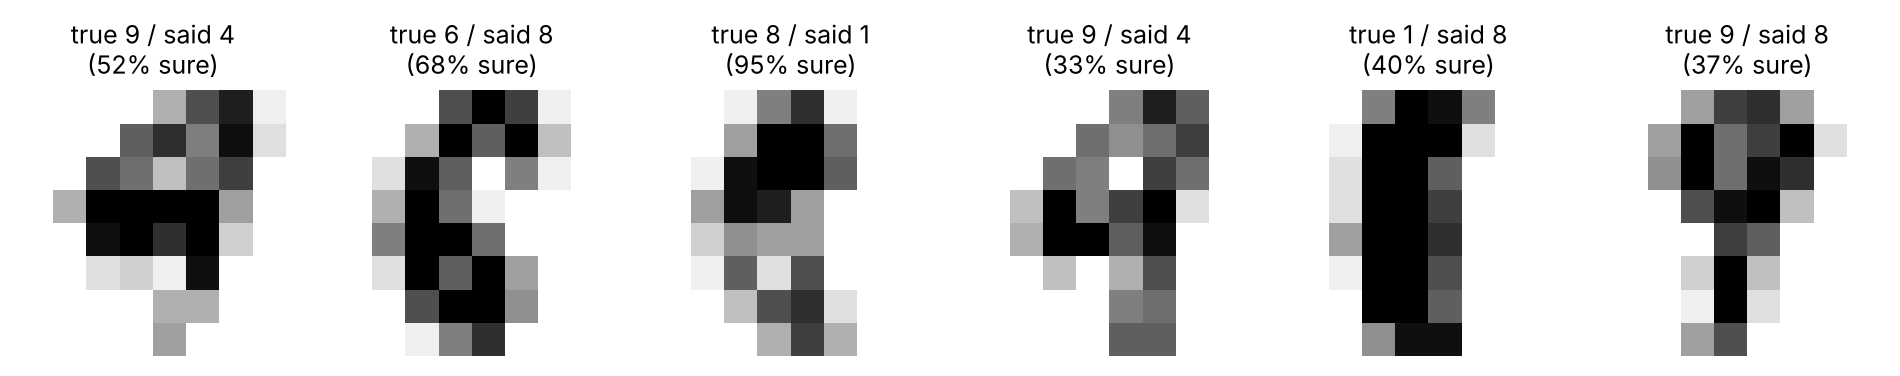

In [20]:
with torch.no_grad():
    probs = torch.softmax(net(X_te), dim=1)
pred = probs.argmax(dim=1)
wrong = (pred != y_te).nonzero().ravel()[:6]
print('test images misread:', int((pred != y_te).sum()), 'of', len(y_te))
fig, ax = plt.subplots(1, len(wrong), figsize=(2 * len(wrong), 2.4))
for a, i in zip(np.atleast_1d(ax), wrong):
    a.imshow(X_te[i].reshape(8, 8), cmap='gray_r'); a.axis('off')
    a.set_title(f'true {y_te[i].item()} / said {pred[i].item()}\n({probs[i, pred[i]].item():.0%} sure)', fontsize=9)
plt.show()

Many mistakes are digits that are genuinely hard to read even for a person at 8 × 8 pixels. Notice the network gives a **probability** for every digit, just as an LLM gives a probability for every possible next word.

## B5 · Save and reload

In [21]:
torch.save(net.state_dict(), 'digits_net.pt')
net2 = nn.Sequential(nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 10))
net2.load_state_dict(torch.load('digits_net.pt'))
print('reloaded model predicts first 10 test digits:', net2(X_te[:10]).argmax(dim=1).tolist())
print('true labels                                 :', y_te[:10].tolist())

reloaded model predicts first 10 test digits: [5, 2, 8, 1, 7, 2, 6, 2, 6, 5]
true labels                                 : [5, 2, 8, 1, 7, 2, 6, 2, 6, 5]


## Summary
| Step | What you built |
|---|---|
| A1 | a neuron = weighted sum + activation (= logistic regression) |
| A2 | why activations: stacked linear layers collapse into one |
| A3 | one neuron can't solve XOR |
| A4–A5 | forward pass with matrices; cross-entropy loss |
| A6 | backpropagation = chain rule backwards, checked numerically |
| A7 | training from scratch solves XOR and the moons |
| B1–B2 | PyTorch: autograd + the 5-line training loop |
| B3–B5 | a digit reader (~97% on unseen images), mistakes, saving |

**Bridge to LLMs:** GPT uses the same pieces: layers of weights, activations, softmax over the vocabulary, cross-entropy loss, backpropagation and Adam. What it adds is a way to read **sequences of words**: tokens, embeddings and **attention** (Parts 2 and 3).

## Exercises
1. In A7, change the hidden layer to 2 neurons. Can it still solve XOR? Try several seeds.
2. In B3, add a second hidden layer (`nn.Linear(64, 64), nn.ReLU()`). Does test accuracy improve?
3. Train B3 for 200 epochs. Does the gap between train and test accuracy grow? What is this called?